# QueueSense — Walt Disney World Orlando EDA

This notebook validates the three Kaggle files used by the dashboard before defining its planning metrics. The target user is a travel-company itinerary product manager. The analysis distinguishes a historical planning baseline from current Queue-Times API data; it does not claim a precise future forecast.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
calendar = pd.read_csv(ROOT / 'data' / 'calendar_enriched.csv', parse_dates=['date'])
rides = pd.read_csv(ROOT / 'data' / 'ride_stats.csv')
pass_classes = pd.read_csv(ROOT / 'data' / 'll_classification.csv')
REFERENCE_YEARS = [2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024, 2025]
reference = calendar.loc[calendar['year'].isin(REFERENCE_YEARS)].copy()
active_rides = rides.loc[(rides['year'].astype(str) == 'all_time') & (rides['metric'] == 'ride_avg_wait') & (rides['is_archived'] == 0)].copy()
active_with_pass = active_rides.merge(pass_classes[['park_id', 'ride_id', 'll_class']], on=['park_id', 'ride_id'], how='left')
calendar.shape, rides.shape, pass_classes.shape, reference.shape, active_rides.shape

((16682, 17), (2022, 8), (51, 4), (13142, 17), (83, 8))

## 1. Structure, dates, missingness, and duplicates

In [2]:
quality = pd.Series({
    'calendar_rows': len(calendar),
    'calendar_columns': calendar.shape[1],
    'date_start': calendar['date'].min().date(),
    'date_end': calendar['date'].max().date(),
    'duplicate_park_dates': calendar.duplicated(['park_name', 'date']).sum(),
    'missing_operating_minutes': calendar['operating_minutes'].isna().sum(),
    'reference_rows': len(reference),
    'active_all_time_ride_records': len(active_rides),
})
display(quality.to_frame('value'))
display(calendar.dtypes.to_frame('dtype'))
display(calendar.isna().sum().loc[lambda s: s.gt(0)].to_frame('missing'))

,value
calendar_rows,16682
calendar_columns,17
date_start,2015-01-01
date_end,2026-09-30
duplicate_park_dates,0
missing_operating_minutes,630
reference_rows,13142
active_all_time_ride_records,83


,dtype
park_id,int64
park_name,str
date,datetime64[us]
year,int64
month,int64
month_name,str
day_of_week,str
dow_number,int64
is_weekend,int64
crowd_level_pct,int64


,missing
operating_minutes,630


Each calendar row is one park-day. Only `operating_minutes` is incomplete, so it is excluded from the recommendation score. Duplicate park-dates would make historical comparison cells overweighted; none should remain.

## 2. Coverage balance and reference-period choice

,park_days
park_name,
Animal Kingdom,4173
Magic Kingdom,4173
Hollywood Studios,4169
Epcot,4167


park_name,Animal Kingdom,Epcot,Hollywood Studios,Magic Kingdom
year,,,,
2015,365,365,365,365
2016,366,366,366,366
2017,365,365,365,365
2018,365,365,365,365
2019,365,365,365,365
2020,249,245,245,249
2021,365,365,365,365
2022,365,363,365,365
2023,365,365,365,365


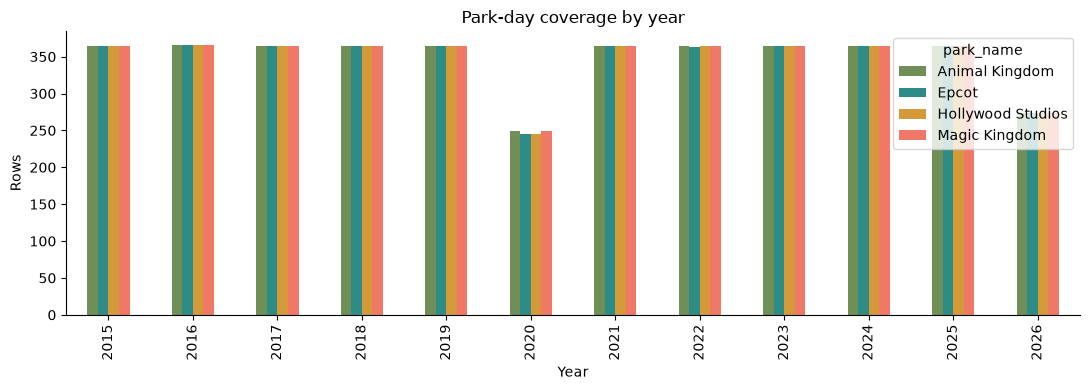

In [3]:
park_counts = calendar.groupby('park_name').size().sort_values(ascending=False)
year_counts = calendar.groupby(['year', 'park_name']).size().unstack(fill_value=0)
display(park_counts.to_frame('park_days'))
display(year_counts)

ax = year_counts.plot(kind='bar', figsize=(11, 4), color=['#6F8F56', '#2E8C87', '#D49A3A', '#F07867'])
ax.set(title='Park-day coverage by year', xlabel='Year', ylabel='Rows')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

The four parks are closely balanced. The recommendation reference uses 2015–2019 and 2022–2025: the exceptional 2020–2021 operating period and incomplete 2026 period are not used to estimate a normal comparable date.

## 3. Historical index distribution and comparable-cell support

,crowd_rel_to_year
count,13142.000000
mean,0.999992
std,0.483970
min,0.000000
25%,0.642250
50%,1.020000
75%,1.330750
max,3.148000


,value
comparison_cells,336.000000
minimum_days_per_cell,36.000000
median_days_per_cell,39.000000
maximum_days_per_cell,41.000000
share_at_or_above_1.10,0.434561
share_at_or_above_1.20,0.352458


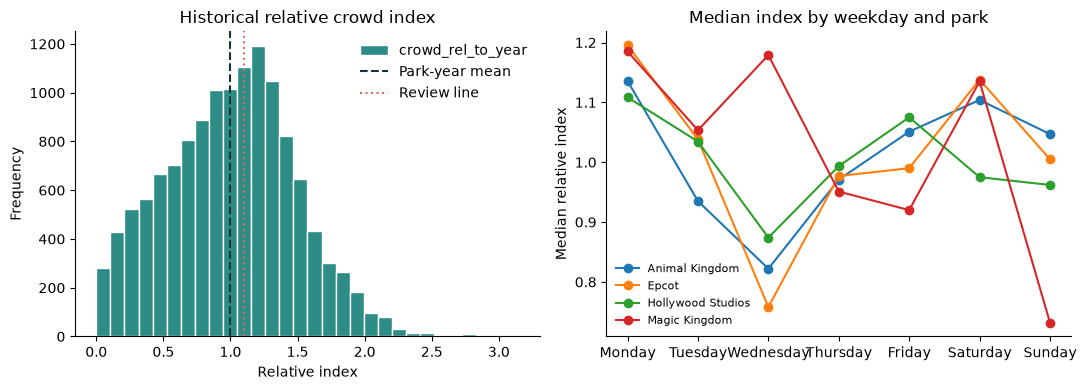

In [4]:
summary = reference['crowd_rel_to_year'].describe(percentiles=[.25, .5, .75]).to_frame('crowd_rel_to_year')
cells = reference.groupby(['park_name', 'month', 'day_of_week']).size()
display(summary)
display(pd.Series({
    'comparison_cells': len(cells),
    'minimum_days_per_cell': cells.min(),
    'median_days_per_cell': cells.median(),
    'maximum_days_per_cell': cells.max(),
    'share_at_or_above_1.10': (reference['crowd_rel_to_year'] >= 1.10).mean(),
    'share_at_or_above_1.20': (reference['crowd_rel_to_year'] >= 1.20).mean(),
}).to_frame('value'))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
reference['crowd_rel_to_year'].plot.hist(bins=30, color='#2E8C87', edgecolor='white', ax=axes[0])
axes[0].axvline(1.0, color='#14343B', linestyle='--', label='Park-year mean')
axes[0].axvline(1.10, color='#E16958', linestyle=':', label='Review line')
axes[0].set(title='Historical relative crowd index', xlabel='Relative index')
axes[0].legend(frameon=False)
weekday = reference.groupby(['day_of_week', 'park_name'])['crowd_rel_to_year'].median().unstack()
weekday = weekday.reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
weekday.plot(marker='o', ax=axes[1])
axes[1].set(title='Median index by weekday and park', xlabel='', ylabel='Median relative index')
axes[1].legend(frameon=False, fontsize=8)
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

All same-park × month × weekday cells contain enough observations to display a median, middle 50% interval, and sample size. Values remain descriptive source indices; zero and extreme values are retained because the CSV does not provide a reliable relabeling rule.

## 4. Attraction context coverage

,active_attractions,median_source_all_time_wait,maximum_source_all_time_wait
park_name,,,
Animal Kingdom,10,27.5,81
Epcot,18,14.0,63
Hollywood Studios,15,40.0,71
Magic Kingdom,40,24.0,67


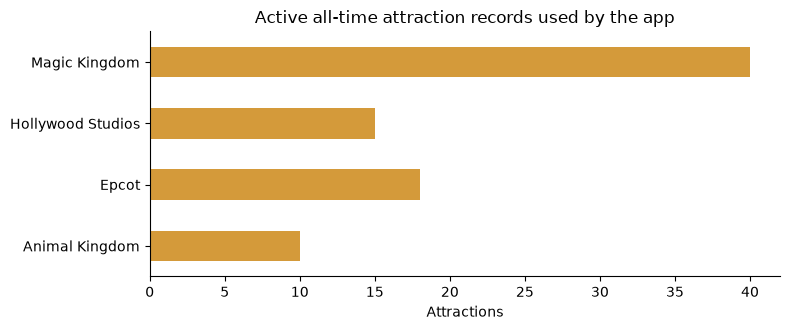

In [5]:
ride_coverage = active_rides.groupby('park_name').agg(
    active_attractions=('ride_name', 'nunique'),
    median_source_all_time_wait=('minutes', 'median'),
    maximum_source_all_time_wait=('minutes', 'max'),
).sort_index()
display(ride_coverage)
assert not active_rides.duplicated(['park_name', 'ride_name']).any()

ax = ride_coverage['active_attractions'].plot(kind='barh', color='#D49A3A', figsize=(8, 3.4))
ax.set(title='Active all-time attraction records used by the app', xlabel='Attractions', ylabel='')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

Must-do attractions are used as park-coverage constraints. Their source-published all-time average minutes may be shown as context, but they do not produce a selected-date attraction forecast.

In [6]:
pass_summary = pd.concat([
    pass_classes['ll_class'].value_counts().rename('source_rows'),
    active_with_pass['ll_class'].value_counts().rename('active_matches'),
], axis=1).fillna(0).astype(int)
display(pass_summary)
print('Park IDs represented in ll_classification:', sorted(pass_classes['park_id'].unique()))
print('Active attractions without a matched label:', int(active_with_pass['ll_class'].isna().sum()))
assert set(pass_classes['park_id']) == {6}
assert active_with_pass['ll_class'].notna().sum() == 40

,source_rows,active_matches
ll_class,,
multi_pass,18,18
exclude,17,10
none,14,10
single_pass,2,2


Park IDs represented in ll_classification: [np.int64(6)]
Active attractions without a matched label: 43


The pass-classification snapshot covers Magic Kingdom (`park_id = 6`) only. It matches 40 active attraction rows; 43 active attractions in the other parks have no matched label. The app therefore uses the supplied class where present and displays **Verify access** everywhere else. It never extrapolates a Magic Kingdom label to another park.

## 5. Metric and interface decisions

The final dashboard keeps three top metrics: historical trip-pressure, higher-pressure visits, and must-do coverage. It keeps one selected-route pressure chart and compact project-priority cards. A map, visitor-count claim, future exact wait prediction, weather causality, and large raw table are excluded because the files do not support them or they do not improve the itinerary decision.

The live API is not part of this EDA snapshot. It is a separate five-minute operational feed with attribution and an offline fallback.